# 2. Stage 1: Noise

Sensitivity depends on total noise: **external noise** collected by the antenna, plus the **receiver's** own. From 50 MHz to 18 GHz, each source dominates in a different part of the band.

## External noise: Rec. ITU-R P.372

Median man-made noise follows

$$F_{am} = c - d\log_{10} f_{\mathrm{MHz}}$$

| Category | c | d |
|---|---|---|
| City | 76.8 | 27.7 |
| Residential | 72.5 | 27.7 |
| Rural | 67.2 | 27.7 |
| Quiet rural | 53.6 | 28.6 |
| Galactic | 52.0 | 23.0 |

**Source:** all from P.372-18 (09/2026): eq. 17, Table 1, and Figs 3 and 39.

**Validity, which matters for this tool's 50 MHz to 18 GHz range:**

- **City, residential, rural:** eq. 17 holds from 0.3 to 250 MHz. Fig. 3 curve A shows city noise flattening to about -11.5 dB per decade above about 175 MHz, out to about 900 MHz. Above 250 MHz, the tool continues from the eq. 17 value at that slope. Using it for other categories, and above 900 MHz, is this tool's assumption, so it is flagged. Enter a measured value if it matters.
- **Quiet rural:** Fig. 39 stops this curve at 30 MHz, because it is ionospherically reflected noise seen only below $f_xF_2$. It is therefore **rejected** across this tool's range, leaving galactic noise.
- **Galactic:** eq. 15 is stated up to about 100 MHz. Fig. 3 curve B continues close to the same slope to about 5 GHz, so the tool uses it there. Below about three times $f_oF_2$, the ionosphere reduces it.

The factors refer to a short vertical monopole over a perfect ground plane, 4.77 dBi.

Atmospheric gases and rain emit as absorbers do (P.372-18 eq. 10):

$$T_b = T_{mr}\left(1-10^{-A/10}\right) + 2.73\cdot 10^{-A/10}$$

$T_{mr}$ is 275 K for rain. For clear air, P.372-18 uses a data file that isn't bundled here, so the tool uses 275 K for both. This has little effect, because the emission is small.

Lightning noise is listed as **rejected**: it matters at HF and lower VHF, and is negligible against man-made and galactic noise at 50 MHz and above.

Noise also varies with time and place. The last section below covers this.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
# Run from the notebooks folder, or from the project root.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from bistatic_lb import Scenario, run_link_budget, plots

from bistatic_lb.noise.itu_p372 import man_made_fam_db, galactic_fam_db, fa_to_temperature_k

for cat in ("city", "residential", "rural", "quiet_rural"):
    print(f"{cat:12s} Fam at 100 MHz = {man_made_fam_db(100e6, cat):5.1f} dB, {fa_to_temperature_k(man_made_fam_db(100e6, cat)):8.0f} K")
print(f"galactic     Fam at 100 MHz = {galactic_fam_db(100e6):5.1f} dB")


city         Fam at 100 MHz =  21.4 dB,    40031 K
residential  Fam at 100 MHz =  17.1 dB,    14873 K
rural        Fam at 100 MHz =  11.8 dB,     4389 K
quiet_rural  Fam at 100 MHz =  -3.6 dB,      127 K
galactic     Fam at 100 MHz =   6.0 dB


## Which source limits sensitivity?

The P.372 factors refer to a short vertical monopole, so they cannot be applied to another antenna unchanged. The tool integrates sky and ground over the actual pattern, and scales the man-made value by the antenna's gain near the horizon.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


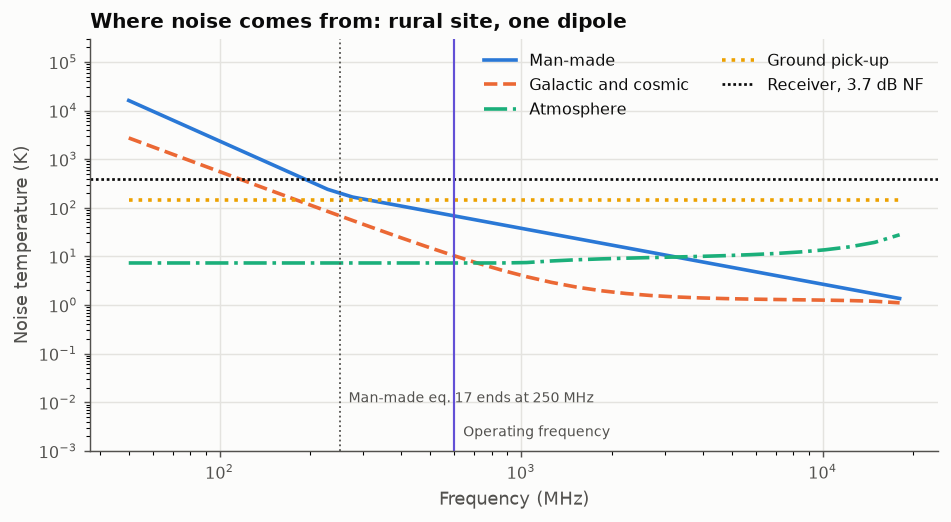

In [2]:
s = Scenario()
plots.noise_vs_frequency(s); plt.show()


Reading the chart:

- **Below a few hundred MHz**, external noise exceeds this receiver. A better LNA will not help much, and a higher-gain antenna gains signal but not SNR against diffuse noise unless the beam also rejects it.
- **In the middle of the band**, ground pick-up and the receiver dominate. Here LNA noise figure matters.
- **Above about 10 GHz**, atmospheric absorption starts to climb.

## Array gain differs for the two kinds of noise

Receiver noise is uncorrelated between channels, so beamforming leaves it unchanged. External noise is spatially correlated, so its output level follows the pattern:

$$T_{\mathrm{out}} = \frac{1}{4\pi}\int |w^H a(\Omega)|^2\, T(\Omega)\, d\Omega + T_{\mathrm{rx}}$$

So a large array gives its full gain only where receiver noise dominates.

At close spacing, the no-coupling model overstates both signal gain and external noise at the output, which is why the external value below rises after beamforming. Mutual coupling in a real array removes most of this, and the tool warns when the effect is above 1.5 dB.

In [3]:
r = run_link_budget(s)
print(r.noise.array_noise_gain_note)
print(f"System temperature {r.noise.system_output_k:.0f} K; dominant source: {r.noise.dominant_source}")
print()
for c in r.noise.contributions:
    print(f"{c.name:38s} {c.value:9.2f} K  used: {str(c.applicable):5s}  {c.reason}")


Receiver noise is unchanged by beamforming (387 K), while external noise goes from 227 K per element to 320 K at the output.
System temperature 707 K; dominant source: receiver

Man-made noise                            101.17 K  used: True   P.372 median for the 'rural' category. Above 1% of receiver noise.
Galactic and cosmic background             13.98 K  used: True   Falls about 23 dB per decade, so it matters most at VHF and low UHF.
Atmospheric gases and rain emission        10.67 K  used: True   Zenith gas absorption 0.032 dB; absorbers emit at about 275 K.
Ground pick-up                            194.03 K  used: True   The dipole pattern is not shielded from the ground, which radiates at about 290 K.
Sun in beam                                 0.00 K  used: False  Disabled: the beam is not assumed to point at the Sun.
Lightning (atmospheric) noise               0.00 K  used: False  Rejected: an HF and lower-VHF effect, negligible against man-made and galactic noise at 50 MHz 

## Receiver noise: the Friis cascade

$$F = F_1 + \frac{F_2-1}{G_1} + \frac{F_3-1}{G_1G_2} + \dots$$

Every loss ahead of the LNA adds directly to the noise figure, including the limiter and the filter needed to protect it.

In [4]:
for row in r.lineup.table():
    print(row)
print(f"Receiver: NF {r.lineup.noise_figure_db:.2f} dB, {r.lineup.noise_temperature_k:.0f} K, IIP3 {r.lineup.iip3_dbm:.1f} dBm")


{'Stage': 'Feed', 'Gain (dB)': -0.5, 'NF (dB)': 0.5, 'IIP3 (dBm)': '-', 'Cumulative gain (dB)': -0.5, 'Cumulative NF (dB)': 0.5}
{'Stage': 'Limiter', 'Gain (dB)': -0.5, 'NF (dB)': 0.5, 'IIP3 (dBm)': '-', 'Cumulative gain (dB)': -1.0, 'Cumulative NF (dB)': 1.0}
{'Stage': 'RF filter', 'Gain (dB)': -1.0, 'NF (dB)': 1.0, 'IIP3 (dBm)': '-', 'Cumulative gain (dB)': -2.0, 'Cumulative NF (dB)': 2.0}
{'Stage': 'LNA', 'Gain (dB)': 25.0, 'NF (dB)': 1.5, 'IIP3 (dBm)': '15.0', 'Cumulative gain (dB)': 23.0, 'Cumulative NF (dB)': 3.5}
{'Stage': 'Mixer', 'Gain (dB)': -7.0, 'NF (dB)': 7.0, 'IIP3 (dBm)': '20.0', 'Cumulative gain (dB)': 16.0, 'Cumulative NF (dB)': 3.54}
{'Stage': 'IF amplifier', 'Gain (dB)': 28.0, 'NF (dB)': 6.0, 'IIP3 (dBm)': '15.0', 'Cumulative gain (dB)': 44.0, 'Cumulative NF (dB)': 3.68}
Receiver: NF 3.68 dB, 387 K, IIP3 -5.2 dBm


### Trade-off: does a better LNA help here?

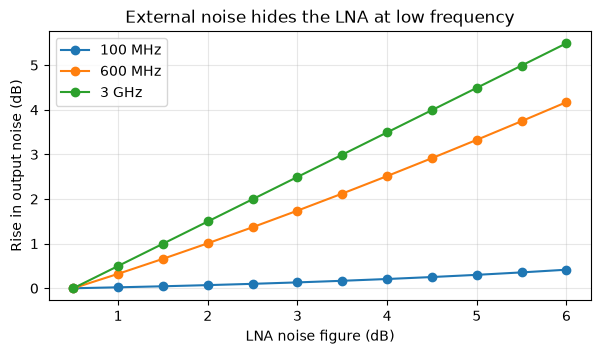

In [5]:
from bistatic_lb.sweeps import sweep
fig, ax = plt.subplots(figsize=(7, 3.5))
nf = np.linspace(0.5, 6, 12)
for f, name in ((100e6, "100 MHz"), (600e6, "600 MHz"), (3e9, "3 GHz")):
    base = s.with_value("frequency_hz", f).with_value("environment.man_made_category", "residential")
    _, y = sweep(base, "frontend.lna_nf_db", nf, "Noise density at array output (dBm/Hz)")
    ax.plot(nf, y - y[0], marker="o", label=name)
ax.set(xlabel="LNA noise figure (dB)", ylabel="Rise in output noise (dB)", title="External noise hides the LNA at low frequency"); ax.grid(alpha=0.3); ax.legend(); plt.show()


## Noise spread: P.372-18 Part 7

Medians alone hide how far noise moves. P.372-18 models each source's noise figure with two half-normal distributions, with $\sigma = D/1.282$ from its decile deviation $D$. Table 2 gives man-made deviations with time and with location, which are uncorrelated and so add in power. Galactic noise has $\sigma = 1.56$ dB.

The sum of sources follows from eq. 31 to 35, with $c = 10/\ln 10$:

$$\alpha_T = \sum_i \exp\left(\frac{F_{am,i}}{c} + \frac{\sigma_i^2}{2c^2}\right),\quad \beta_T = \sum_i \alpha_i^2\left[\exp\left(\frac{\sigma_i^2}{c^2}\right)-1\right]$$

$$\sigma_T = c\sqrt{\ln\left(1+\frac{\beta_T}{\alpha_T^2}\right)},\quad F_{amT} = c\left[\ln\alpha_T - \frac{\sigma_T^2}{2c^2}\right],\quad D_{uT} = 1.282\,\sigma_T$$

If a component's deviation exceeds 12 dB, eq. 38 limits $\sigma_T$.

**Two choices of this tool:**

- Part 7 is applied only to man-made and galactic noise. Receiver, ground and atmosphere are held constant and added afterwards. Moment-matching a sum that includes a large constant gives a poor result, and can even put the median below that constant.
- Eq. 31 does not say which deviations give the median. The upper set is used, because that sets the design margin.

### Check: Part 7 against simulation

This draws each source from its two half-normal distributions and compares the sum with the closed form.

In [6]:
from bistatic_lb.noise.statistics import man_made_decile_deviations_db, noise_statistics

rng = np.random.default_rng(3)
def two_piece(median_k, upper_db, lower_db, n):
    z = rng.standard_normal(n)
    return median_k * 10 ** (np.where(z > 0, z * upper_db / 1.282, z * lower_db / 1.282) / 10)

print(f"{'Man-made K':>11s}{'Category':>13s}{'Upper K (Part 7 / sim)':>26s}{'Median K (Part 7 / sim)':>26s}")
for t_mm in (100.0, 1000.0, 10000.0):
    for category in ("rural", "city"):
        up, low = man_made_decile_deviations_db(category)
        st = noise_statistics(t_mm, 50.0, 400.0, up, low)
        total = two_piece(t_mm, up, low, 400_000) + two_piece(50.0, 2.0, 2.0, 400_000) + 400.0
        print(f"{t_mm:11.0f}{category:>13s}{st.system_upper_k:13.0f} /{np.quantile(total, 0.9):11.0f}{st.system_median_k:13.0f} /{np.median(total):11.0f}")


 Man-made K     Category    Upper K (Part 7 / sim)   Median K (Part 7 / sim)
        100        rural         1918 /       1858          513 /        558
        100         city         3364 /       2863          550 /        558
       1000        rural        14456 /      14262         1413 /       1450
       1000         city        25221 /      24450         1450 /       1453
      10000        rural       139848 /     139725        10413 /      10519


      10000         city       243148 /     242990        10450 /      10416


### This design, and what it means for detection

System noise: lower decile 609 K, sum of medians 707 K, upper decile 2036 K
Upper-decile margin: 4.6 dB
Table 2 is an average for 0.3 to 250 MHz, used here beyond its range. Older outdoor measurements at 322-425 MHz (P.372-13) show smaller deviations, so this margin may be pessimistic. Enter measured deviations if available.


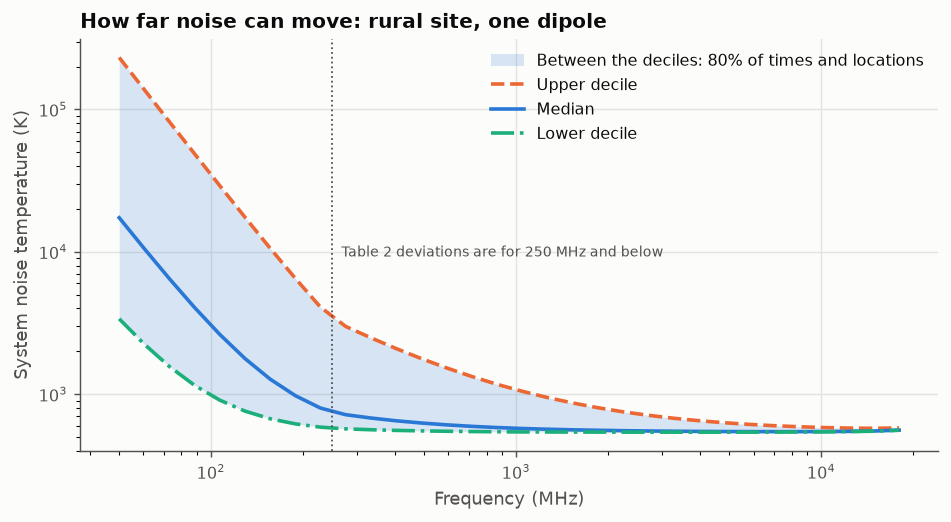

 Frequency     Category  Margin dB  Pd median  Pd upper
     100MHz         city       13.7      0.965     0.482


     100MHz        rural       10.2      0.995     0.951
     250MHz         city       12.9      0.976     0.649


     250MHz        rural        6.9      0.992     0.966


     600MHz         city       11.8      0.905     0.271


     600MHz        rural        4.6      0.954     0.880


    3000MHz         city        7.5      0.129     0.001


    3000MHz        rural        1.3      0.177     0.109


In [7]:
st = r.noise.statistics
print(f"System noise: lower decile {st.system_lower_k:.0f} K, sum of medians {st.system_sum_of_medians_k:.0f} K, upper decile {st.system_upper_k:.0f} K")
print(f"Upper-decile margin: {st.upper_margin_db:.1f} dB")
if st.note:
    print(st.note)
plots.noise_spread_vs_frequency(s); plt.show()

print(f"{'Frequency':>10s}{'Category':>13s}{'Margin dB':>11s}{'Pd median':>11s}{'Pd upper':>10s}")
for f in (100e6, 250e6, 600e6, 3e9):
    for category in ("city", "rural"):
        x = run_link_budget(s.with_value("frequency_hz", f).with_value("environment.man_made_category", category))
        print(f"{f/1e6:8.0f}MHz{category:>13s}{x.noise.statistics.upper_margin_db:11.1f}{x.detection.pd:11.3f}{x.detection.pd_upper_decile:10.3f}")


The spread matters most where man-made noise dominates, at VHF and low UHF. Higher up, the receiver and ground dominate, so the margin shrinks. Table 2 is an average for 0.3 to 250 MHz, and older outdoor measurements at 322-425 MHz (P.372-13) show smaller deviations, so results above 250 MHz may be pessimistic.

To design for this, set `environment.noise_design_point` to `upper_decile`. The rest of the link then uses that noise level.